In [1]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import SMS_map
importlib.reload(SMS_map)
from SMS_map import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import DTT_func
importlib.reload(DTT_func)
from DTT_func import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\PaP_calculate_quantitative_signal')
import PaP_quantitative_acoustic_study_plot
importlib.reload(PaP_quantitative_acoustic_study_plot)
from PaP_quantitative_acoustic_study_plot import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\PaP_calculate_quantitative_signal')
import PaP_quantitative_acoustic_study_func
importlib.reload(PaP_quantitative_acoustic_study_func)
from PaP_quantitative_acoustic_study_func import *



os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Linear_spectra_meas')
from Spectra_computation_func import *
import Spectra_computation_func
importlib.reload(Spectra_computation_func)
from Spectra_computation_func  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
from FWHM_treatment_func import *
import FWHM_treatment_func
importlib.reload(FWHM_treatment_func)
from FWHM_treatment_func  import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

# Get the raw experimental data

In [21]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study'
#dir_root += r'\Silice thick 4,5 - D1 zone1'
dir_root += r'\Silice thick 4,5 - D2 zone1'
#dir_root += r'\Membrane 3,5 - ND3,5-5'
#dir_root += r'\Sapphire 2,3 - NDd zone 3'


dir_root_raw_data = dir_root + r'\Extinction variation calculation'
os.chdir(dir_root_raw_data)

fname_acoustic = 'acoustic_raw_data.dat'
Data_acoustic = get_raw_data(dir_root_raw_data, fname_acoustic)


In [22]:
for key in Data_acoustic :
    print(key)

date
lambda_probe
detuning
detuning_normalised
x_LP2
P_ini
polar
A_ac
abs(A_ac)
A_ac_err
tau_ac
tau_ac_err
T_ac
T_ac_err
phi
phi_err
f1
f1_red_1D_est
Q
Q_err
Comment


# Get the FWHM calibration of the probe

In [23]:
# get calib
if dir_root.endswith(r'\Silice thick 4,5 - D1 zone1') :
    dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\Jun 2025'


    Source_list = ['OPO', 'SHG']
    FWHM_data = get_FWHM_data(dir_calib, Source_list)
    WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_2D_mean']

    WL_calib_probe, FWHM_calib_probe = WL_calib['OPO'], FWHM_calib['OPO']


if dir_root.endswith(r'\Silice thick 4,5 - D2 zone1') :
    dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\2026-04'


    Source_list = ['OPO', 'SHG']
    FWHM_data = get_FWHM_data(dir_calib, Source_list)
    WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_1D_mean']

    WL_calib_probe, FWHM_calib_probe = WL_calib['OPO'], FWHM_calib['OPO']


if dir_root.endswith(r'\Membrane 3,5 - ND3,5-5') :
    dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\March 2025'


    Source_list = ['OPO', 'SHG']
    FWHM_data = get_FWHM_data(dir_calib, Source_list)
    WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_2D_mean']

    WL_calib_probe, FWHM_calib_probe = WL_calib['OPO'], FWHM_calib['OPO']

if dir_root.endswith(r'\Sapphire 2,3 - NDd zone 3') :
    dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\March 2025'
        
    Source_list = ['OPO', 'SHG']
    FWHM_data = get_FWHM_data(dir_calib, Source_list)
    WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_2D_mean']

    WL_calib_probe, FWHM_calib_probe = WL_calib['OPO'], FWHM_calib['OPO']


# Get the linear spectra of the object

In [24]:
#define delta_y
delta_y = 300e-9

#get spectra

if dir_root.endswith(r'\Sapphire 2,3 - NDd zone 3') :
    Spectra_dic_tot = Spectra_computation(dir_root, 'Linear spectra', WL_calib, FWHM_calib, delta_y, Source_list, other_title = '21-Jan-2025-Spectre_theta_0', force_recomputation=False, spectra_title = '21-Jan-2025-Spectre_theta_0', method='fine')
    
if dir_root.endswith(r'\Membrane 3,5 - ND3,5-5') :
    Spectra_dic_tot = Spectra_computation(dir_root, 'Linear spectra', WL_calib, FWHM_calib, delta_y, Source_list, other_title = '13-Mar-2025-Spectre_theta_90', force_recomputation=False, spectra_title = '13-Mar-2025-Spectre_theta_90', method='fine')

if dir_root.endswith(r'\Silice thick 4,5 - D1 zone1') :
    Spectra_dic_tot = Spectra_computation(dir_root, 'Linear spectra', WL_calib, FWHM_calib, delta_y, Source_list, other_title = '01-Jul-2025-Spectre_theta_170', force_recomputation=False, spectra_title = '01-Jul-2025-Spectre_theta_170', method='fine')

if dir_root.endswith(r'\Silice thick 4,5 - D2 zone1') :
    Spectra_dic_tot = Spectra_computation(dir_root, 'Linear spectra', WL_calib, FWHM_calib, delta_y, Source_list, other_title = '15-Apr-2026-Spectre_theta_0', force_recomputation=False, spectra_title = '15-Apr-2026-Spectre_theta_0', method='fine')


Spectra_dic = Spectra_dic_tot['file']['OPO']

Linear spectra already treated


In [25]:
for key in Spectra_dic :
    print(key)

Lambda
DTT
Voff
V
DTT_corr (1e-3)
Sigma (nm2)
Sigma_err (nm2)


# Get the pump calibration information

In [26]:
os.chdir(dir_root)
fname_pump = 'pump_characteristic.dat'
Pump_calib_data = get_raw_data(dir_root, fname_pump)

# Quantitative data treatment

Here we make a first correction to take into account that the measure power in the detector is attenuated by the linear extinction of the nano-object

In [27]:
alpha_PaP = 1 #Chopper conversion coefficient : it is already implemented in the lab software, so I set it to 1 here. Otherwise it is 2.55

if dir_root.endswith(r'\Silice thick 4,5 - D2 zone1') :
    alpha_PaP = 2.55 # For this study the coefficient wasn't there


compute_corrected_DTT_signal_acoustic(Data_acoustic, Spectra_dic, FWHM_calib_probe, WL_calib_probe, alpha_PaP=alpha_PaP)

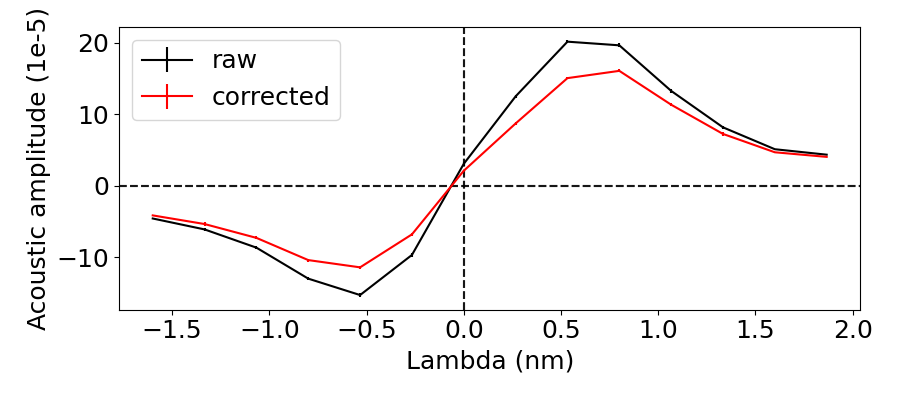

In [28]:
fig, ax  = plt.subplots(figsize=(9,4))
plot_A_raw_coeff(Data_acoustic, ax, alpha_PaP=alpha_PaP)
plot_A_corrected_coeff(Data_acoustic, ax)


ax.legend()

plt.tight_layout()

# Calculate $\Delta \sigma_\mathrm{ext}$

In [29]:
Compute_delta_sigma_acoustic(Data_acoustic, FWHM_calib_probe, WL_calib_probe)

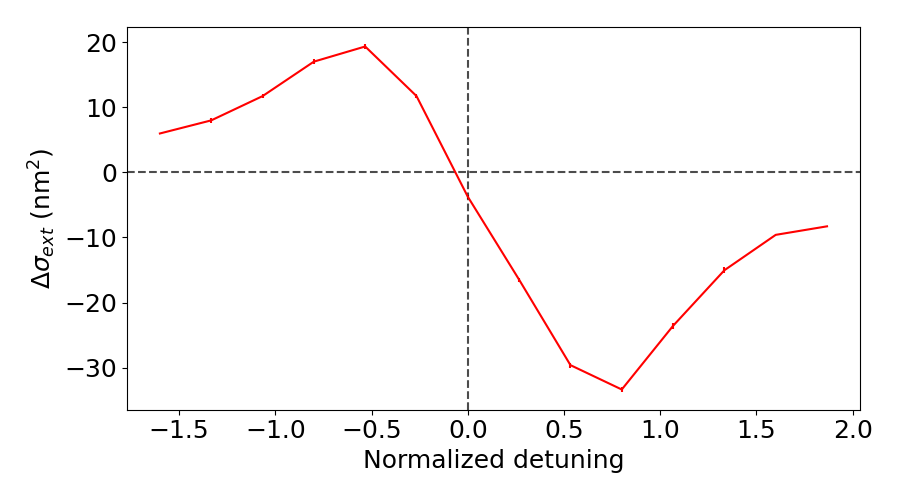

In [30]:
fig, ax  = plt.subplots(figsize=(9,5))

plot_Delta_sigma_acoustic(Data_acoustic, ax)
plt.tight_layout()

# Calculate $\Delta T_0$

The temparature elevation is defined by $\Delta T_0 = \frac{E_{abs}}{C}$


with $E_{abs} = \sigma_{abs, 0}(\lambda_{pump}) \frac{E_{pulse}}{S_{pump}}$ the absorbed energy at each impulsion

and C = $c_V V$ the thermal capacity of the nanoparticle (V is its volume, $c_V$ its volumic thermal capacity)




### Important parameters

In [ ]:
t_chopper = 1 #attenuation coefficient of the mechanical chopper (equal to 1 i the power was measured without the chopper)
f_rep = 80e6 #laser repetition rate
lda_pump = 410 #pump wavelength in nm.
c_V = 	2.492 *1e6 #Volumic capacity in S.I.

if dir_root.endswith(r'\Sapphire 2,3 - NDd zone 3') :
    sigma_abs_pump = 5415.65  #sigma_abs(lda_pump) in nm2
    D = 92e-9 #diameter
    h = 24e-9 #height


if dir_root.endswith(r'\Membrane 3,5 - ND3,5-5') :
    sigma_abs_pump = 4043.21  #sigma_abs(lda_pump) in nm2
    D = 81e-9 #diameter
    h = 18e-9 #height

if dir_root.endswith(r'\Silice thick 4,5 - D1 zone1') :
    sigma_abs_pump = 7911.18  #sigma_abs(lda_pump) in nm2
    D = 102.25e-9 #diameter
    h = 21.9e-9 #height


if dir_root.endswith(r'\Silice thick 4,5 - D2 zone1') : #To be determined
    sigma_abs_pump = 8726  #sigma_abs(lda_pump) in nm2
    D = 109.4e-9 #diameter
    h = 23.5e-9 #height



V = np.pi*(D/2)**2*h

C = V*c_V #total heat capacity of the nanodisk

### Calculated $E_{pulse}$, energy in a single pulse

#### from $E_{pulse} = \frac{P_i t_{chopper} t_{objective}}{f_{rep}}$

In [32]:
compute_E_pulse(Data_acoustic, Pump_calib_data, t_chopper, f_rep)

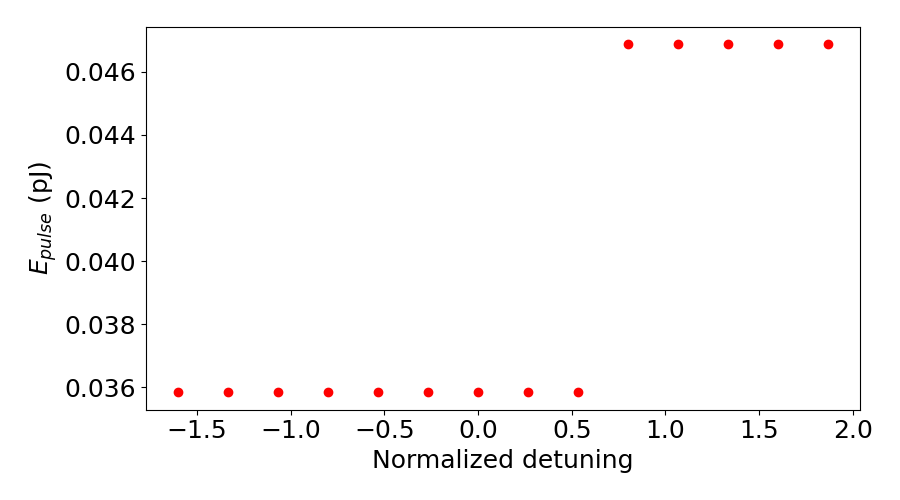

In [33]:
fig, ax  = plt.subplots(figsize=(9,5))

plot_E_pulse(Data_acoustic, ax)

plt.tight_layout()

Calculate $\Delta T_0$

In [34]:
compute_Delta_T(Data_acoustic, Pump_calib_data, sigma_abs_pump, C=C)


Data_acoustic['Delta_sigma_ac_normalized'] = Data_acoustic['Delta_sigma_ac']/ Data_acoustic['Delta_T']
Data_acoustic['Delta_sigma_ac_normalized_err'] = np.abs(Data_acoustic['Delta_sigma_ac_err']/ Data_acoustic['Delta_T'])

Fluence : 0.45363017514327253 J/m2
Fluence : 0.45363017514327253 J/m2
Fluence : 0.45363017514327253 J/m2
Fluence : 0.45363017514327253 J/m2
Fluence : 0.45363017514327253 J/m2
Fluence : 0.45363017514327253 J/m2
Fluence : 0.45363017514327253 J/m2
Fluence : 0.45363017514327253 J/m2
Fluence : 0.45363017514327253 J/m2
Fluence : 0.5635712436380068 J/m2
Fluence : 0.5635712436380068 J/m2
Fluence : 0.5635712436380068 J/m2
Fluence : 0.5635712436380068 J/m2
Fluence : 0.5635712436380068 J/m2


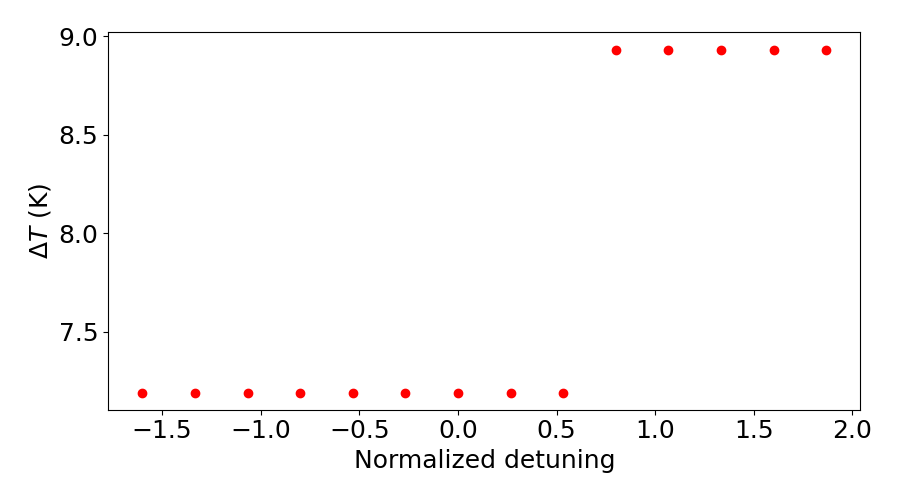

In [35]:
fig, ax  = plt.subplots(figsize=(9,5))

plot_Delta_T(Data_acoustic, ax)

plt.tight_layout()

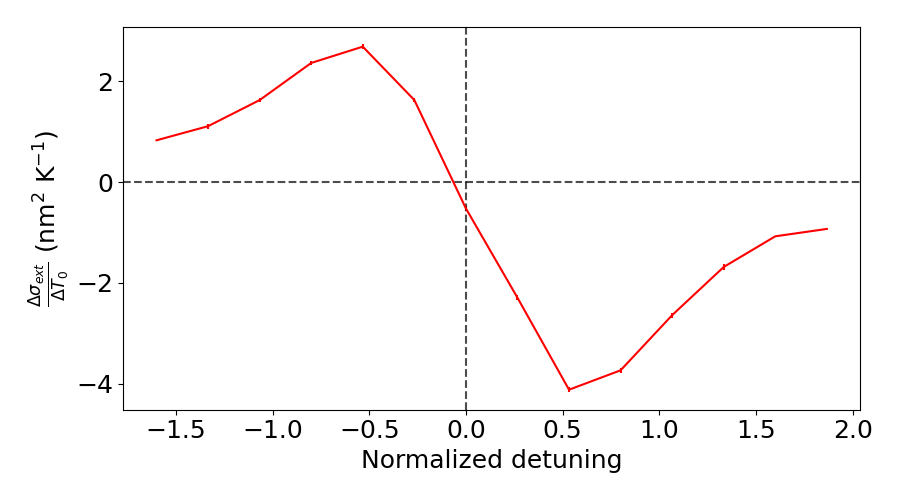

In [36]:
fig, ax  = plt.subplots(figsize=(9,5))

plot_Delta_sigma_acoustic_normalized(Data_acoustic, ax)


plt.tight_layout()

In [37]:
full_normalize_sigma(Data_acoustic, Spectra_dic)

# Save_data

In [38]:
dir_to_save = dir_root + r'\Extinction variation calculation'
fname = 'Treated_experimental_data_acoustic.csv'

save_treated_PaP_signal_acoustic(Data_acoustic, dir_to_save, fname)